Importing Libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA

Dataset Uploading

In [4]:
uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Saving WEEK 6 Cleaned_Dataset.csv to WEEK 6 Cleaned_Dataset (1).csv
Dataset loaded successfully!
Dataset Shape: (180519, 53)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,59405.0,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,59405.0,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,59405.0,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,59405.0,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,59405.0,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


Select features and target

In [9]:
target_column = 'Late_delivery_risk'

numeric_features = [
    'Days for shipment (scheduled)',
        'Benefit per order',
            'Sales per customer',
                'Order Item Discount',
                    'Order Item Discount Rate',
                        'Order Item Product Price',
                            'Order Item Quantity',
                                'Sales',
                                    'Order Item Total',
                                        'Order Item Profit Ratio',
                                            'Product Price'
                                            ]

categorical_features = [
                                                'Type',
                                                    'Category Name',
                                                        'Customer Segment',
                                                            'Department Name',
                                                                'Market',
                                                                    'Order Region',
                                                                        'Shipping Mode'
                                                                        ]
df = df.dropna(subset=[target_column]).copy()
for col in numeric_features:
    df[col] = pd.to_numeric(df[col], errors='coerce')
X = df[numeric_features + categorical_features].copy()
y = df[target_column].copy()
print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (180519, 18)
y Shape: (180519,)


Split the dataset into training and testing data

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
      X,
          y,
              test_size=0.20,
                  random_state=42,
                      stratify=y
                      )
print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

Training Data Shape: (144415, 18)
Testing Data Shape: (36104, 18)


Preprocessing

In [11]:
numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
        ])
try:
    onehot = OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
                                )
except TypeError:
    onehot = OneHotEncoder(
        handle_unknown='ignore',
        sparse=False
                                                        )
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', onehot)
                                                                ])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_pipeline, numeric_features),
        ('cat', categorical_pipeline, categorical_features)
    ],
    sparse_threshold=0
                                                                                            )
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)
print("Preprocessing completed!")
print("Processed Training Shape:", X_train_processed.shape)
print("Processed Testing Shape:", X_test_processed.shape)

Preprocessing completed!
Processed Training Shape: (144415, 111)
Processed Testing Shape: (36104, 111)


Feature Selection using ANOVA Test

In [12]:
# Get the names of the processed features
feature_names = preprocessor.get_feature_names_out()

# Apply ANOVA feature selection
k = min(10, X_train_processed.shape[1])

anova_selector = SelectKBest(
    score_func=f_classif,
    k=k
        )

X_train_selected = anova_selector.fit_transform(
    X_train_processed,
    y_train
                )

X_test_selected = anova_selector.transform(
    X_test_processed
                    )


selected_mask = anova_selector.get_support()
selected_features = feature_names[selected_mask]
print("Top Selected Features using ANOVA:")
for feature in selected_features:
    print(feature)

print("\nNumber of Features Before Selection:", len(feature_names))
print("Number of Features After Selection:", len(selected_features))

Top Selected Features using ANOVA:
num__Days for shipment (scheduled)
cat__Type_CASH
cat__Type_DEBIT
cat__Type_PAYMENT
cat__Type_TRANSFER
cat__Order Region_Western Europe
cat__Shipping Mode_First Class
cat__Shipping Mode_Same Day
cat__Shipping Mode_Second Class
cat__Shipping Mode_Standard Class

Number of Features Before Selection: 111
Number of Features After Selection: 10


Display ANOVA scores and graph

Top 10 Features based on ANOVA:


,Feature,ANOVA F-Score,P-Value
110,cat__Shipping Mode_Standard Class,29056.697011,0.000000e+00
0,num__Days for shipment (scheduled),22781.259848,0.000000e+00
107,cat__Shipping Mode_First Class,19748.799453,0.000000e+00
109,cat__Shipping Mode_Second Class,7030.246190,0.000000e+00
14,cat__Type_TRANSFER,896.252080,2.566549e-196
108,cat__Shipping Mode_Same Day,271.267809,6.827471e-61
12,cat__Type_DEBIT,211.780718,6.072620e-48
13,cat__Type_PAYMENT,133.466868,7.373612e-31
11,cat__Type_CASH,20.625101,5.590399e-06
106,cat__Order Region_Western Europe,18.568127,1.640470e-05


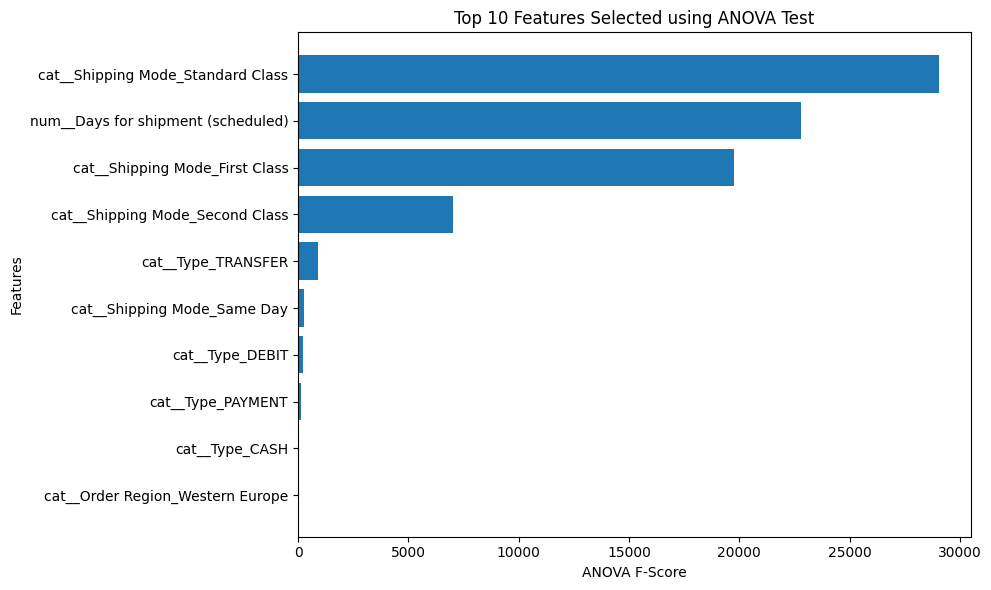

In [13]:
anova_results = pd.DataFrame({
    'Feature': feature_names,
    'ANOVA F-Score': anova_selector.scores_,
    'P-Value': anova_selector.pvalues_
              })
anova_results = anova_results.replace(
    [np.inf, -np.inf], np.nan
).dropna(subset=['ANOVA F-Score'])

anova_results = anova_results.sort_values(
    by='ANOVA F-Score',
    ascending=False
                          )

print("Top 10 Features based on ANOVA:")
display(anova_results.head(10))

top_features = anova_results.head(10).sort_values(
    by='ANOVA F-Score'
                              )

plt.figure(figsize=(10, 6))

plt.barh(
    top_features['Feature'],
    top_features['ANOVA F-Score']
                                      )

plt.xlabel("ANOVA F-Score")
plt.ylabel("Features")
plt.title("Top 10 Features Selected using ANOVA Test")
plt.tight_layout()
plt.show()

Apply PCA

In [14]:
pca = PCA(
      n_components=0.95,
          svd_solver='full'
          )
X_train_pca = pca.fit_transform(X_train_selected)

X_test_pca = pca.transform(X_test_selected)
print("PCA Applied Successfully!")
print("Features Before PCA:", X_train_selected.shape[1])
print("Principal Components After PCA:", X_train_pca.shape[1])
print(
      "Total Variance Retained:",
      round(np.sum(pca.explained_variance_ratio_) * 100, 2),
      "%"
                      )

PCA Applied Successfully!
Features Before PCA: 10
Principal Components After PCA: 6
Total Variance Retained: 96.36 %


Visualize cumulative explained variance

Components required to retain 95% variance: 6
Cumulative Variance: 96.36 %


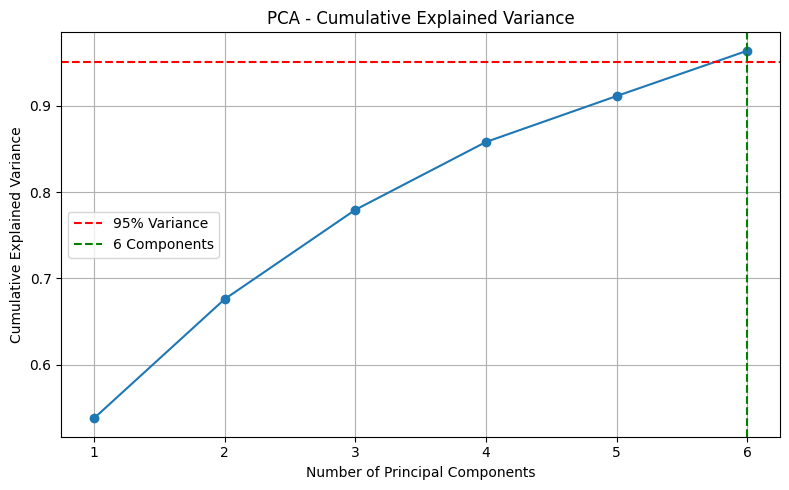

In [16]:
cumulative_variance = np.cumsum(
    pca.explained_variance_ratio_
    )

components_95 = np.argmax(cumulative_variance >= 0.95) + 1

print(
    "Components required to retain 95% variance:",
      components_95
            )
print(
    "Cumulative Variance:",
    round(cumulative_variance[components_95 - 1] * 100, 2),
    "%"
                        )
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='o'
                                    )
plt.axhline(
    y=0.95,
    color='red',
    linestyle='--',
    label='95% Variance'
                                                    )
plt.axvline(
    x=components_95,
    color='green',
    linestyle='--',
    label=f'{components_95} Components'
                                                                    )
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Cumulative Explained Variance")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

PCA visualization

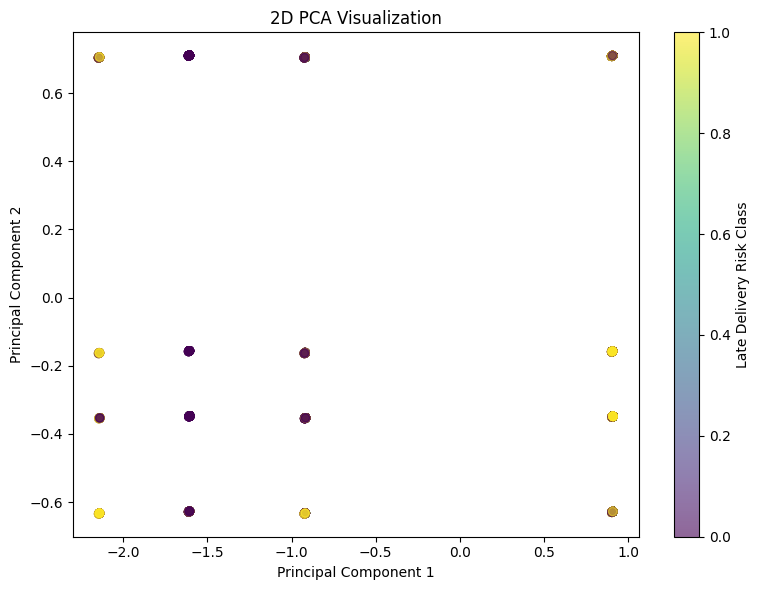

Variance explained by first 2 components: 67.6 %


In [20]:
pca_2d = PCA(n_components=2)

X_train_pca_2d = pca_2d.fit_transform(X_train_selected)

sample_size = min(3000, len(X_train_pca_2d))

rng = np.random.RandomState(42)

sample_indices = rng.choice(
    len(X_train_pca_2d),
    size=sample_size,
    replace=False
            )

plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    X_train_pca_2d[sample_indices, 0],
    X_train_pca_2d[sample_indices, 1],
    c=pd.factorize(y_train)[0][sample_indices],
    cmap='viridis',
    alpha=0.6
                                )
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("2D PCA Visualization")
plt.colorbar(scatter, label="Late Delivery Risk Class")
plt.tight_layout()
plt.show()
print(
     "Variance explained by first 2 components:",
      round(np.sum(pca_2d.explained_variance_ratio_) * 100, 2),
      "%"
                                            )

In [21]:


anova_train_df = pd.DataFrame(
    X_train_selected,
        columns=["ANOVA_" + str(name) for name in selected_features]
        )

pca_columns = [
            "PC" + str(i + 1)
                for i in range(X_train_pca.shape[1])
                ]
pca_train_df = pd.DataFrame(
                    X_train_pca,
                        columns=pca_columns
                        )

final_df = pd.concat(
                            [
                                    X_train.reset_index(drop=True),
                                            y_train.reset_index(drop=True).rename("Late_delivery_risk"),
                                                    anova_train_df.reset_index(drop=True),
                                                            pca_train_df.reset_index(drop=True)
                                                                ],
                                                                    axis=1
                                                                    )
output_file = "Final_Cleaned_ANOVA_PCA_Dataset.csv"
final_df.to_csv(output_file, index=False)
files.download(output_file)
print("Dataset downloaded successfully!")
print("Final Dataset Shape:", final_df.shape)
display(final_df.head())


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Dataset downloaded successfully!
Final Dataset Shape: (144415, 35)


,Days for shipment (scheduled),Benefit per order,Sales per customer,Order Item Discount,Order Item Discount Rate,Order Item Product Price,Order Item Quantity,Sales,Order Item Total,Order Item Profit Ratio,...,ANOVA_cat__Shipping Mode_First Class,ANOVA_cat__Shipping Mode_Same Day,ANOVA_cat__Shipping Mode_Second Class,ANOVA_cat__Shipping Mode_Standard Class,PC1,PC2,PC3,PC4,PC5,PC6
0,4,23.500000,50.000000,0.0,0.00,50.000000,1,50.000000,50.000000,0.47,...,0.0,0.0,0.0,1.0,0.905136,-0.350001,0.820731,-0.100368,0.749708,0.435031
1,4,35.389999,97.489998,32.5,0.25,129.990005,1,129.990005,97.489998,0.36,...,0.0,0.0,0.0,1.0,0.907711,-0.627870,-0.573028,-0.057376,-0.014311,-0.193117
2,1,43.189999,95.980003,24.0,0.20,59.990002,2,119.980003,95.980003,0.45,...,1.0,0.0,0.0,0.0,-1.609841,-0.349016,0.803978,-0.634986,0.754490,0.424557
3,2,78.019997,165.990005,34.0,0.17,199.990005,1,199.990005,165.990005,0.47,...,0.0,0.0,1.0,0.0,-0.919923,0.705757,-0.082852,0.803163,-0.068373,-0.159759
4,2,173.990005,347.980011,52.0,0.13,399.980011,1,399.980011,347.980011,0.50,...,0.0,0.0,1.0,0.0,-0.919923,0.705757,-0.082852,0.803163,-0.068373,-0.159759
